# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнила студентка гр. 3381 Киреева Асия Эдуардовна. Вариант №7.

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

### 1. Линейные дискретные системы

Линейная дискретная система преобразует входную последовательность $x(n)$ в выходную $y(n)$. В рекурсивной системе выход зависит как от входных отсчетов, так и от предыдущих значений выхода.

Передаточная функция звена второго порядка:

$$
H(z)=\frac{Y(z)}{X(z)}=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}}.
$$

Соответствующее разностное уравнение:

$$
y(n)=\sum_{i=0}^{2}b_ix(n-i)-\sum_{i=1}^{2}a_iy(n-i).
$$

### 2. Импульсная характеристика и свертка

Импульсная характеристика $h(n)$ - реакция системы на единичный импульс $\delta(n)$ при нулевых начальных условиях:

$$
h(n)=Z^{-1}\{H(z)\}.
$$

Для рекурсивного звена ее длительность обычно бесконечна. Выходной сигнал линейной стационарной системы вычисляется сверткой:

$$
y(n)=\sum_{m=-\infty}^{+\infty}x(m)h(n-m).
$$

Длина полной свертки двух конечных последовательностей:

$$
L=N_1+N_2-1.
$$

### 3. Нули, полюсы и устойчивость

Нули передаточной функции - корни числителя, полюсы - корни знаменателя:

$$
H(z)=K\frac{(1-z_1z^{-1})(1-z_2z^{-1})}{(1-p_1z^{-1})(1-p_2z^{-1})}.
$$

Причинная рекурсивная система устойчива, если все ее полюсы расположены внутри единичной окружности:

$$
|p_i|<1.
$$

При наличии комплексно-сопряженных полюсов импульсная характеристика имеет колебательный характер, а при $|p_i|<1$ колебания затухают.

### 4. Частотные характеристики системы

Частотная характеристика получается подстановкой $z=e^{j\omega}$ в передаточную функцию.

АЧХ определяет зависимость усиления от частоты, а ФЧХ - изменение фазы:

$$
A(\omega)=|H(e^{j\omega})|,\qquad
\varphi(\omega)=\arg H(e^{j\omega}).
$$

Связь абсолютной и нормированной угловой частот:

$$
f=\frac{\omega f_d}{2\pi},\qquad
\hat{\omega}=\frac{\omega}{\pi}.
$$

Частота Найквиста:

$$
f_{\text{Н}}=\frac{f_d}{2}.
$$

### 5. Дискретное преобразование Фурье

ДПФ представляет конечную последовательность в виде комплексных спектральных коэффициентов:

$$
X(k)=\sum_{n=0}^{N-1}x(n)e^{-j2\pi kn/N}.
$$

Обратное ДПФ позволяет восстановить исходную последовательность:

$$
x(n)=\frac{1}{N}\sum_{k=0}^{N-1}X(k)e^{j2\pi kn/N}.
$$

Двусторонний амплитудный и фазовый спектры периодической последовательности:

$$
A(k)=\frac{|X(k)|}{N},\qquad
\varphi(k)=\arg X(k).
$$

Частотное разрешение ДПФ:

$$
\Delta f=\frac{f_d}{N}.
$$

Для одностороннего спектра амплитуды гармоник на положительных частотах ниже частоты Найквиста равны $2|X(k)|/N$.

### 6. Восстановление аналогового сигнала

Периодический аналоговый сигнал восстанавливается по коэффициентам ДПФ:

$$
x(t)=\frac{1}{N}\sum_{k=-N/2}^{N/2-1}X_a(k)e^{j2\pi kt/(NT)},
$$

где $X_a(k)$ - коэффициенты ДПФ, упорядоченные от отрицательных частот к положительным.

Для точного восстановления исходного сигнала в рассматриваемом случае частоты гармоник должны быть ниже частоты Найквиста и совпадать с частотной сеткой ДПФ.

### 7. Равенство Парсеваля

Равенство Парсеваля показывает, что энергия конечной последовательности сохраняется при переходе из временной области в частотную с учетом нормировки:

$$
\sum_{n=0}^{N-1}|x(n)|^2=\frac{1}{N}\sum_{k=0}^{N-1}|X(k)|^2.
$$

Для периодической последовательности средняя мощность за период равна:

$$
P=\frac{1}{N}\sum_{n=0}^{N-1}|x(n)|^2.
$$

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

### Часть 1

In [1]:
# импорты
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

In [2]:
# вычисление значений переменных на основе номера варианта
N_var = 7

b0 = 0.5 + 0.02 * N_var
b1 = b0 * (-1)**(N_var + 1) * (0.9822 + 0.0178 * N_var)
b2 = b0 * (0.8 + 0.2 * (N_var % 5))

a0 = 1
a1 = (-1)**N_var * (0.7778 + 0.025 * N_var)
a2 = 0.64 + 0.006 * N_var

N1 = N_var % 10 + 20
N2 = N_var % 10 + 30

fd = 1000 * N_var

b = np.array([b0, b1, b2])
a = np.array([a0, a1, a2])

print("b =", b)
print("a =", a)
print("N1 =", N1)
print("N2 =", N2)
print("fd =", fd, "Гц")

b = [0.64     0.708352 0.768   ]
a = [ 1.     -0.9528  0.682 ]
N1 = 27
N2 = 37
fd = 7000 Гц


#### Пункт 1
Вычислить импульсную характеристику длины $N_1$ по заданной передаточной функции с коэффициентами $b_i, a_k$ и построить ее график. Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий. Пояснить, чему в действительности равна длина импульсной характеристики.

##### 1.1 Импульсная характеристика и ее график

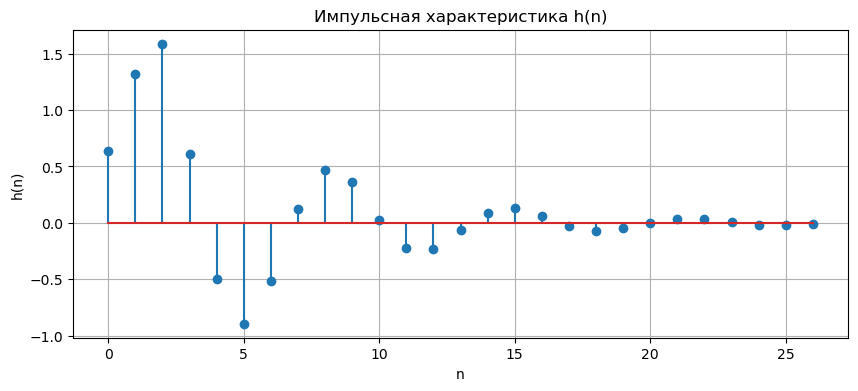

Импульсная характеристика:
[ 0.64        1.318144    1.5874476   0.61354587 -0.49805276 -0.89298295
 -0.51116217  0.12197905  0.46483425  0.35970435  0.02570935 -0.2208225
 -0.22793346 -0.06657405  0.09201886  0.13307907  0.06404088 -0.02974178
 -0.07201385 -0.0483309   0.00306376  0.03588083  0.03209777  0.00611203
 -0.01606714 -0.01947717 -0.00760006]


In [3]:
# Единичный импульс длиной N1
delta = np.zeros(N1)
delta[0] = 1

# Вычисление импульсной характеристики
h = signal.lfilter(b, a, delta)

# Построение графика
n = np.arange(N1)

plt.figure(figsize=(10, 4))
plt.stem(n, h)
plt.title("Импульсная характеристика h(n)")
plt.xlabel("n")
plt.ylabel("h(n)")
plt.grid()
plt.show()

print("Импульсная характеристика:")
print(h)

##### 1.2 Аналитическая формула импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий

Передаточная функция рекурсивного звена 2-го порядка имеет вид:

$$
H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{1+a_1z^{-1}+a_2z^{-2}} =
$$

$$
=\frac{0.64+0.708352z^{-1}+0.768z^{-2}}{1-0.9528z^{-1}+0.682z^{-2}}
$$

Импульсная характеристика определяется обратным Z-преобразованием передаточной функции:

$$
h(n)=Z^{-1}\{H(z)\}
$$

**1. Определение полюсов передаточной функции**

Полюсы являются корнями характеристического уравнения:

$$
z^2+a_1z+a_2=0
$$

Для заданных коэффициентов:

$$
z^2-0.9528z+0.682=0
$$

Вычислим дискриминант:

$$
D=a_1^2-4a_2=(-0.9528)^2-4\cdot0.682=-1.8202
$$

Поскольку $D<0$, уравнение имеет два комплексно-сопряженных корня:

$$
p_{1,2}=\frac{-a_1\pm j\sqrt{|D|}}{2}=0.4764\pm0.674569j
$$

**2. Представление полюсов в показательной форме**

Представим их в показательной форме:

$$
p_{1,2}=\rho e^{\pm j\theta},
$$

где:

$$
\rho=\sqrt{a_2}=\sqrt{0.682}\approx0.825833,
\qquad
\theta=\arccos\left(\frac{-a_1}{2\rho}\right)\approx0.955902\text{ рад}
$$

Таким образом:

$$
p_{1,2}=0.825833e^{\pm j0.955902}
$$

**3. Определение начальных отсчетов импульсной характеристики**

Разностное уравнение системы при $a_0=1$:

$$
h(n)=b_0\delta(n)+b_1\delta(n-1)+b_2\delta(n-2)-a_1h(n-1)-a_2h(n-2)
$$

При нулевых начальных условиях первые три отсчета равны:

$$
h(0)=b_0=0.64
$$

$$
h(1)=b_1-a_1h(0)=1.318144
$$

$$
h(2)=b_2-a_1h(1)-a_2h(0)=1.5874
$$

Начиная с $n=3$, входная импульсная последовательность и ее задержанные значения равны нулю, поэтому система описывается однородным разностным уравнением:

$$
h(n)=-a_1h(n-1)-a_2h(n-2)
$$

**4. Аналитическая формула для случая $D<0$**

Для комплексно-сопряжннных полюсов импульсная характеристика имеет вид:

$$
h(n)=\rho^{n-1}\left(C_1\cos((n-1)\theta)+C_2\sin((n-1)\theta)\right),\quad n\geq1
$$

Константы определяются из начальных отсчетов $h(1)$ и $h(2)$:

$$
C_1=h(1)=1.318144,\qquad C_2=\frac{h(2)/\rho-C_1\cos\theta}{\sin\theta}\approx1.422366
$$

Таким образом, аналитическая формула импульсной характеристики:

$$
h(n)=
\begin{cases}
0.64,&n=0,\\
0.825833^{n-1}\big(1.318144\cos(0.955902(n-1))+1.422366\sin(0.955902(n-1))\big),&n\geq1
\end{cases}
$$

##### 1.3 Длина импульсной характеристики

В рекурсивной системе выход зависит от предыдущих значений выхода. Даже когда входной импульс уже закончился, система продолжает выдавать ненулевые значения. Поэтому импульсная характеристика теоретически бесконечна, но при устойчивой системе постепенно стремится к нулю.

#### Пункт 2
Вычислить реакцию $y_1(n)$ по формуле свертки. В качестве воздействия $x(n)$ длины $N_2$ выбрать дискретный прямоугольный импульс:

$$
x(n) = \begin{cases} 
1, & 0 \leqslant n < int(N_2/2) \\ 
0, & int(N_2/2) \leqslant n \leqslant N_2 - 1 
\end{cases}
$$

где функция $int(t)$ - округление до ближайшего целого. Вывести графики воздействия и реакции. Пояснить:

a. чему равна длина импульса $x$;

b. чему равна длина свертки аналитически и по графику;

c. почему ее ограничивают до длины воздействия.

Длина полной свертки: 63
Свертка (первые N2 отсчетов): [ 0.64        1.958144    3.5455916   4.15913747  3.66108471  2.76810176
  2.25693958  2.37891864  2.84375288  3.20345724  3.22916659  3.00834409
  2.78041064  2.71383658  2.80585544  2.93893452  3.00297539  2.97323362
  2.90121977  2.21288887  0.89780863 -0.65375814 -1.23520625 -0.73104146
  0.14587436  0.63755936  0.50798025  0.043146   -0.31655835 -0.34226771
 -0.12144521  0.10648825  0.1730623   0.08104344 -0.05203563 -0.11607651
 -0.08633473]


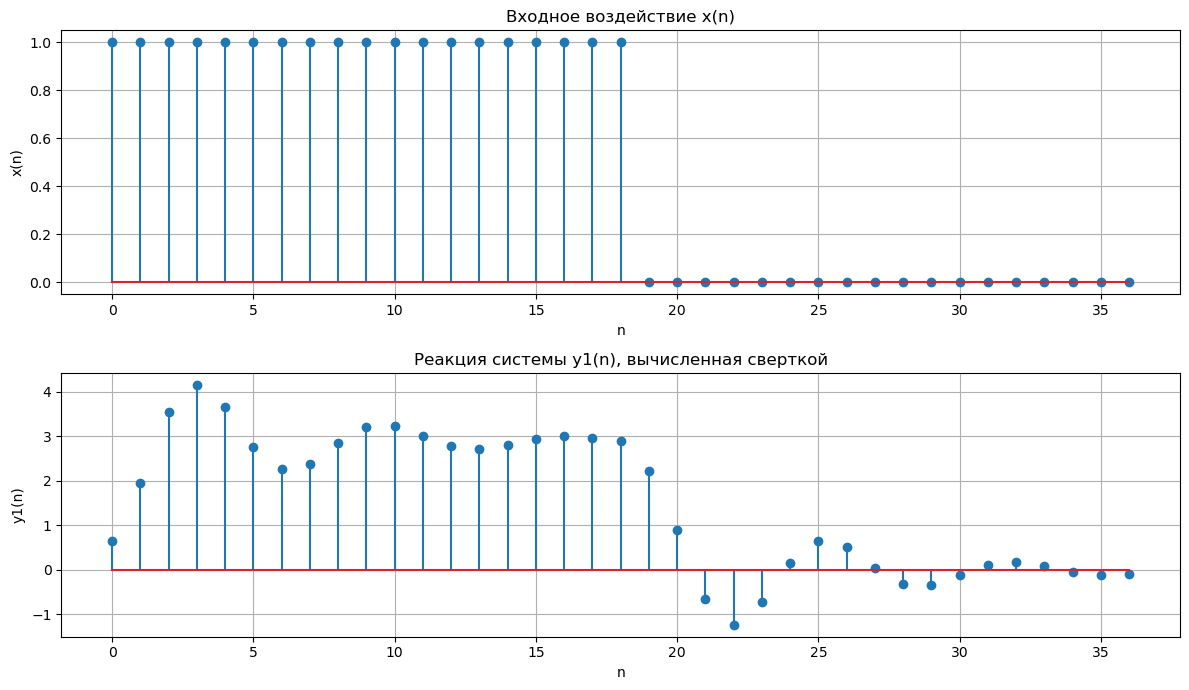

In [4]:
# Формирование входного сигнала
x = np.ones(N2)

x[int(N2 / 2 + 0.5):] = 0

# Вычисление полной свертки
y_conv_full = np.convolve(x, h)

# Длина полной свертки
print("Длина полной свертки:", len(y_conv_full))

# Оставляем первые N2 отсчетов
y1 = y_conv_full[:N2]
print(f'Свертка (первые N2 отсчетов): {y1}')

# Ось времени
n_x = np.arange(N2)
n_y = np.arange(N2)

# Построение графиков
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.stem(n_x, x)
plt.title("Входное воздействие x(n)")
plt.xlabel("n")
plt.ylabel("x(n)")
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(n_y, y1)
plt.title("Реакция системы y1(n), вычисленная сверткой")
plt.xlabel("n")
plt.ylabel("y1(n)")
plt.grid()

plt.tight_layout()
plt.show()

##### 2.1 Чему равна длина импульса $x$?

Длина импульса равна $N_2 = 37$.

##### 2.2 Чему равна длина свертки аналитически и по графику?

Аналитически линейная свертка двух конечных последовательностей длин $N_1$ и $N_2$ имеет длину $N_1 + N_2 - 1 = 27 + 37 - 1 = 63$, что подтверждается результатом программного вычисления. На графике представлены только первые 37 отсчетов для сравнения с реакцией, полученной по разностному уравнению

##### 2.3 Почему свертку ограничивают до длины воздействия?

Полная линейная свертка имеет длину $N_1 + N_2 - 1$, однако для сопоставления с реакцией по разностному уравнению она ограничена длиной воздействия $N_2$.

#### Пункт 3
Вычислить реакцию $y_2(n)$ по разностному уравнению. Задать воздействие $x(n)$ из п. 2. Вывести графики воздействия и реакции. Сравнить графики реакций $y_1(n)$ и $y_2(n)$. Записать разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами. Пояснить, чему равны длины воздействия и реакции.

##### 3.1 Разностное уравнение и построение графиков
Разностное уравнение рекурсивного звена второго порядка (принимаем $a_0=1)$:

$$
y(n)=b_0x(n)+b_1x(n-1)+b_2x(n-2)
-a_1y(n-1)-a_2y(n-2)
= $$
$$
= 0.64x(n)+0.708352x(n-1)
+0.768x(n-2)+0.9528y(n-1)
-0.682y(n-2)
$$

y2: [ 0.64        1.958144    3.5455916   4.15913747  3.66108471  2.76810176
  2.25693958  2.37891864  2.84375288  3.20345724  3.22916659  3.00834409
  2.78041064  2.71383658  2.80585544  2.93893452  3.00297539  2.97323362
  2.90121977  2.21288887  0.89780863 -0.65375814 -1.23520625 -0.73104146
  0.14587436  0.63755936  0.50798025  0.04918809 -0.29957611 -0.3189824
 -0.09961552  0.12263233  0.18478187  0.09242492 -0.03795877 -0.09920091
 -0.06863075]


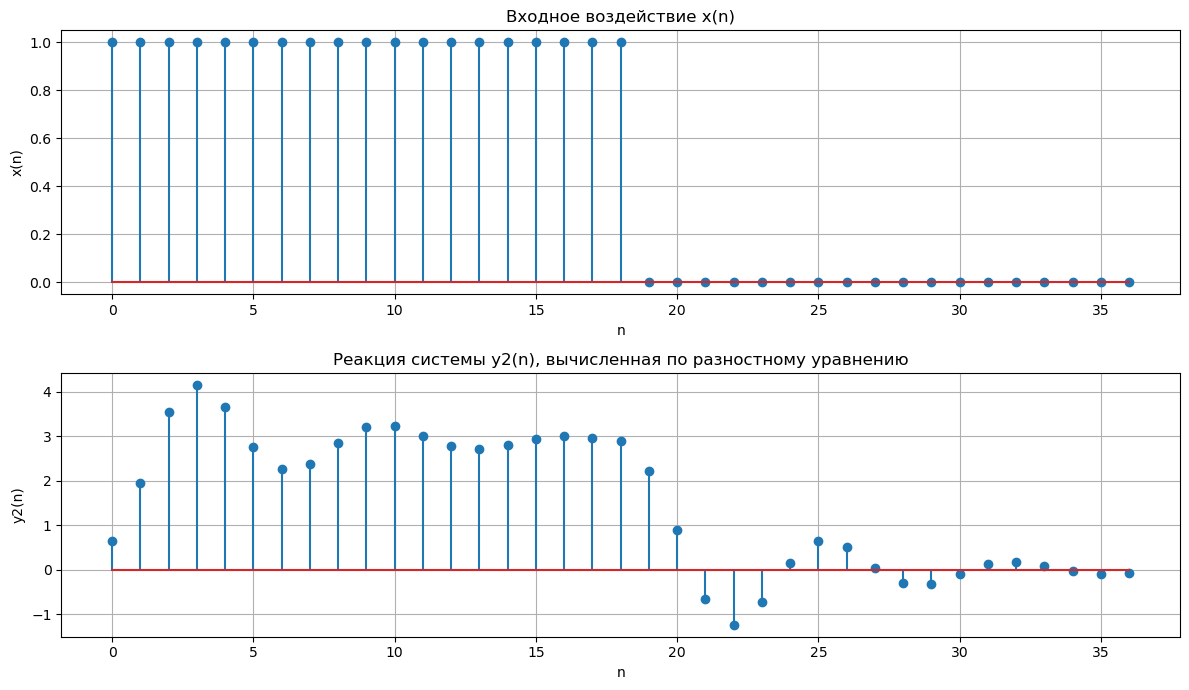

In [5]:
# Массив для выходного сигнала
y2 = np.zeros(N2)

# Вычисление реакции по разностному уравнению
for n in range(N2):
    # Текущие и предыдущие входные отсчеты
    x0 = x[n]
    x1 = x[n - 1] if n >= 1 else 0
    x2 = x[n - 2] if n >= 2 else 0

    # Предыдущие выходные отсчеты
    y_prev1 = y2[n - 1] if n >= 1 else 0
    y_prev2 = y2[n - 2] if n >= 2 else 0

    # Разностное уравнение
    y2[n] = (
        b0 * x0
        + b1 * x1
        + b2 * x2
        - a1 * y_prev1
        - a2 * y_prev2
    )

print(f'y2: {y2}')

# Построение графиков
plt.figure(figsize=(12, 7))

plt.subplot(2, 1, 1)
plt.stem(np.arange(N2), x)
plt.title("Входное воздействие x(n)")
plt.xlabel("n")
plt.ylabel("x(n)")
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(np.arange(N2), y2)
plt.title("Реакция системы y2(n), вычисленная по разностному уравнению")
plt.xlabel("n")
plt.ylabel("y2(n)")
plt.grid()

plt.tight_layout()
plt.show()

##### 3.2 Сравнение реакций системы

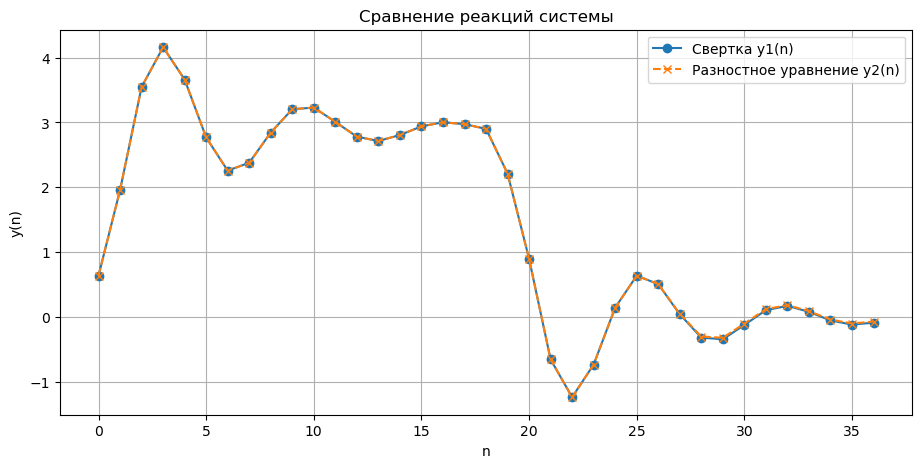

Максимальное абсолютное расхождение: 0.023285303781482247


In [6]:
plt.figure(figsize=(11, 5))

plt.plot(n_y, y1, 'o-', label="Свертка y1(n)")
plt.plot(n_y, y2, 'x--', label="Разностное уравнение y2(n)")

plt.title("Сравнение реакций системы")
plt.xlabel("n")
plt.ylabel("y(n)")
plt.legend()
plt.grid()
plt.show()

# Разность между реакциями
print("Максимальное абсолютное расхождение:",
      np.max(np.abs(y1 - y2)))

Реакция $y_1(n)$, вычисленная через свертку, и реакция $y_2(n)$, полученная рекурсивно по разностному уравнению, практически совпадают. Максимальное расхождение составляет 0.023, что объясняется тем, что при свертке использовалась усеченная импульсная характеристика длины $N_1$.

##### 3.3 Длины воздействия и реакции

- Длина заданной последовательности составляет $N_2=37$ отсчетов, из которых первые 19 имеют значение 1, а оставшиеся 18 - значение 0. Это конечная последовательность, заданная изначально.
- Длина реакции $y_2(n)$ для рекурсивного звена теоретически бесконечна, но в задании обрезана до первых $N_2=37$ значений, чтобы ее можно было корректно сопоставить с обрезанной сверткой $y_1(n)$ на одном и том же временном интервале.

#### Пункт 4

Вычислить нули и полюсы передаточной функции. нули и полюсы в алгебраической и показательной формах и пояснить связь между ними. Выразить значение аргумента полюса и нуля относительно $\pi$. Представить передаточную функцию в виде произведения простейших множителей с нулями и полюсами в показательной форме.

##### 4.1 Нули и полюсы передаточной функции

$$
H(z)=\frac{b_0+b_1 z^{-1}+b_2 z^{-2}}{1+a_1 z^{-1}+a_2 z^{-2}}
=\frac{b_0 z^2+b_1 z+b_2}{z^2+a_1 z+a_2}
$$

In [7]:
# Нули передаточной функции
zeros = np.roots(b)

# Полюсы передаточной функции
poles = np.roots(a)

# Вывод в алгебраической форме
print("Нули передаточной функции:")
for z in zeros:
    print(z)

print("\nПолюсы передаточной функции:")
for p in poles:
    print(p)


# Функция перевода комплексного числа из алгебраической формы в показательную
def polar_form(z):
    r = np.abs(z)
    phi = np.angle(z)
    phi_pi = phi / np.pi

    return r, phi, phi_pi


print("\nНули в показательной форме:")
for z in zeros:
    r, phi, phi_pi = polar_form(z)

    print(f"r = {r:.6f}, "
          f"phi = {phi:.6f} рад, "
          f"phi/pi = {phi_pi:.6f}")


print("\nПолюсы в показательной форме:")
for p in poles:
    r, phi, phi_pi = polar_form(p)

    print(f"r = {r:.6f}, "
          f"phi = {phi:.6f} рад, "
          f"phi/pi = {phi_pi:.6f}")

Нули передаточной функции:
(-0.5534+0.9453826949971108j)
(-0.5534-0.9453826949971108j)

Полюсы передаточной функции:
(0.4763999999999999+0.6745687807777647j)
(0.4763999999999999-0.6745687807777647j)

Нули в показательной форме:
r = 1.095445, phi = 2.100390 рад, phi/pi = 0.668575
r = 1.095445, phi = -2.100390 рад, phi/pi = -0.668575

Полюсы в показательной форме:
r = 0.825833, phi = 0.955902 рад, phi/pi = 0.304273
r = 0.825833, phi = -0.955902 рад, phi/pi = -0.304273


**1. Нули передаточной функции**

В алгебраической форме:
$$
z_1 = -0.5534 + 0.945383 j
$$
$$
z_2 = -0.5534 - 0.945383 j
$$

В показательной форме:
$$
z_1 = 1.095445 \cdot e^{2.100390 j} = 1.095445 \cdot e^{0.668575\pi j}
$$
$$
z_2 = 1.095445 \cdot e^{- 2.100390 j} = 1.095445 \cdot e^{- 0.668575\pi j}
$$

**2. Полюсы передаточной функции**

В алгебраической форме:
$$
p_1 = 0.4764 + 0.674569 j
$$
$$
p_2 = 0.4764 - 0.674569 j
$$

В показательной форме:
$$
p_1 = 0.825833 \cdot e^{0.955902 j} = 0.825833 \cdot e^{0.304273\pi j}
$$
$$
p_2 = 0.825833 \cdot e^{- 0.955902 j} = 0.825833 \cdot e^{- 0.304273\pi j}
$$

##### 4.2 Представление передаточной функции в виде произведения простейших множителей

Общий вид передаточной функции через нули и полюсы:
$$
H(z) = K \frac{(1 - z_1 z^{-1})(1 - z_2 z^{-1})}{(1 - p_1 z^{-1})(1 - p_2 z^{-1})} ,
$$

где $K=b_0=0.64$

После подставления найденных значений нулей и полюсов в показательной форме:
$$
H(z) = 0.64 \cdot \frac{\left(1 - 1.095445 e^{0.668575\pi j} z^{-1}\right)\left(1 - 1.095445 e^{- 0.668575\pi j} z^{-1}\right)}{\left(1 - 0.825833 e^{ 0.304273\pi j} z^{-1}\right)\left(1 - 0.825833 e^{- 0.304273\pi j} z^{-1}\right)}
$$

#### Пункт 5

Изобразить карту нулей и полюсов. Пояснить:

a. является ли рекурсивное звено устойчивым;

b. совпадают ли значения нулей и полюсов с вычисленными в п. 4.

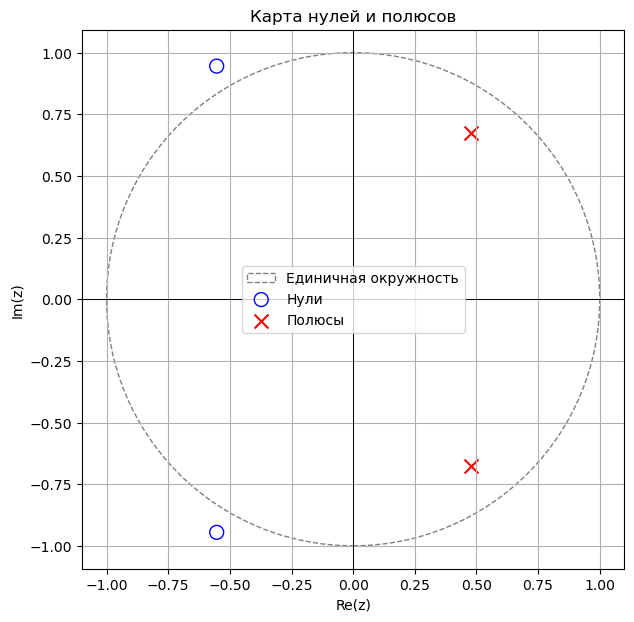

Модули полюсов:
0.825832912882503
0.825832912882503
Система устойчива


In [8]:
# Построение карты нулей и полюсов
plt.figure(figsize=(7, 7))

# Единичная окружность
circle = plt.Circle(
    (0, 0), 1,
    fill=False,
    color='gray',
    linestyle='--',
    label='Единичная окружность'
)

plt.gca().add_patch(circle)

# Нули
plt.scatter(
    zeros.real,
    zeros.imag,
    marker='o',
    facecolors='none',
    edgecolors='blue',
    s=100,
    label='Нули'
)

# Полюсы
plt.scatter(
    poles.real,
    poles.imag,
    marker='x',
    color='red',
    s=100,
    label='Полюсы'
)

plt.axhline(0, color='black', linewidth=0.7)
plt.axvline(0, color='black', linewidth=0.7)

plt.title("Карта нулей и полюсов")
plt.xlabel("Re(z)")
plt.ylabel("Im(z)")

plt.axis('equal')
plt.grid()
plt.legend()
plt.show()


# Проверка устойчивости
print("Модули полюсов:")
for p in poles:
    print(abs(p))

if np.all(np.abs(poles) < 1):
    print("Система устойчива")
else:
    print("Система неустойчива")

**5.1** Система является устойчивой, так как оба полюса находятся внутри единичной окружности.

**5.2** Нули и полюсы совпадают с результатами пункта 4.

#### Пункт 6

Вычислить амплитудно-частотную (АЧХ) и фазочастотную (ФЧХ) характеристики в шкале нормированных частот $\hat{\omega}$ и вывести их графики. Пояснить:

a. чему равны границы основной полосы частот;

b. соответствие между картой нулей и полюсов и видом АЧХ;

c. какому значению АЧХ соответствует скачок на $\pi$, если он имеется;

d. какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции.

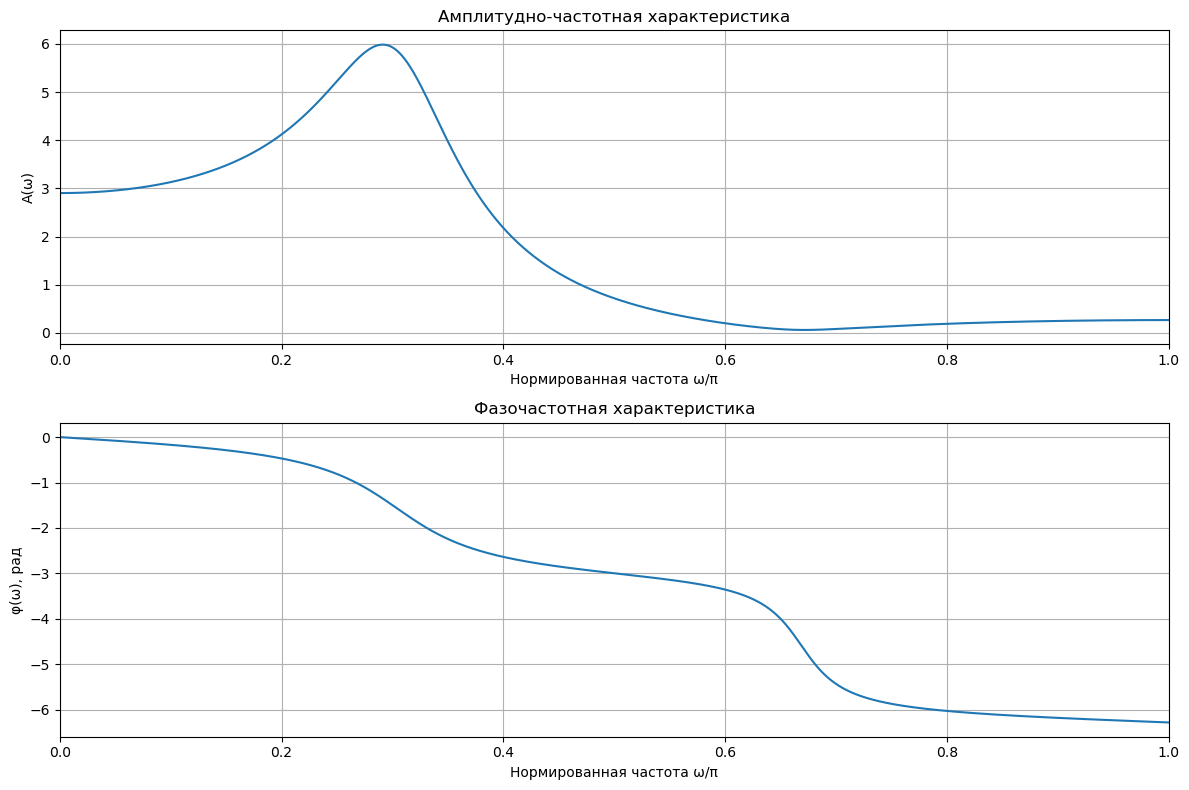

Частота максимума: 0.291016
Максимальная АЧХ: 5.985018


In [14]:
# Вычисление частотной характеристики
w, H = signal.freqz(b, a, worN=2048)

# АЧХ
A = np.abs(H)

# ФЧХ
phi = np.unwrap(np.angle(H))

# Нормированная частота относительно pi
w_norm = w / np.pi

# Построение графиков
plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)
plt.plot(w_norm, A)
plt.title("Амплитудно-частотная характеристика")
plt.xlabel("Нормированная частота ω/π")
plt.ylabel("A(ω)")
plt.xlim(0, 1)
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(w_norm, phi)
plt.title("Фазочастотная характеристика")
plt.xlabel("Нормированная частота ω/π")
plt.ylabel("φ(ω), рад")
plt.xlim(0, 1)
plt.grid()

plt.tight_layout()
plt.show()

idx_max = np.argmax(A)

omega_max = w[idx_max]
omega_norm_max = omega_max / np.pi
A_max = A[idx_max]

print(f"Частота максимума: {omega_norm_max:.6f}")
print(f"Максимальная АЧХ: {A_max:.6f}")

##### 6.1 Чему равны границы основной полосы частот?

Для дискретного сигнала основная полоса частот:
$
0\leq\omega\leq\pi
$

В нормированной шкале:
$
0\leq\omega/\pi\leq1
$

##### 6.2 Соответствие между картой нулей и полюсов и видом АЧХ

Вид АЧХ напрямую определяется расположением нулей и полюсов на комплексной плоскости:

**1. Пик**

Модуль полюсов $r_p = 0.825833$ (близок к 1), а их аргумент составляет $\pm0.304\pi$, что обусловливает появление резонансного пика АЧХ в этой области. Фактический максимум наблюдается при нормированной частоте около 0.291. Чем ближе полюс к единичной окружности, тем острее и выше пик.

**2. Провал:**

Аргумент нулей равен $\pm0.6686\pi$. На графике АЧХ на частоте $\omega/\pi\approx 0.669$ наблюдается глубокий провал. Поскольку модуль нулей $r_z=1.095>1$ (они лежат вне единичной окружности), АЧХ в этой точке не обращается в абсолютный ноль, но принимает минимальное значение.

##### 6.3 Какому значению АЧХ соответствует скачок на $\pi$, если он имеется?

Скачок фазы на $\pi$ может возникать при прохождении частотной характеристики через ноль, то есть при $A(\omega)=0$. В этой точке фаза не определена.

В рассматриваемой системе нули передаточной функции не лежат на единичной окружности, поэтому АЧХ не обращается в ноль и скачка фазы на $\pi$ не наблюдается.

##### 6.4 Какие частотные составляющие подавлены?

- Преимущественно подавлены высокие частоты. Максимальное подавление наблюдается при нормированной частоте около 0,6714, где АЧХ достигает минимума 0,0603. При дальнейшем увеличении частоты АЧХ немного возрастает, однако остается значительно ниже своего максимального значения

- Низкие частоты (в районе $\omega \to 0$) пропускаются с коэффициентом усиления около 3. 

#### Пункт 7

Вычислить АЧХ и ФЧХ в шкале частот $f$ (Гц) при заданной частоте дискретизации $f_d$ и вывести их графики. Пояснить:

a. чему равны границы основной полосы частот;

b. соответствие частотами $\hat{\omega}$ и $f$.

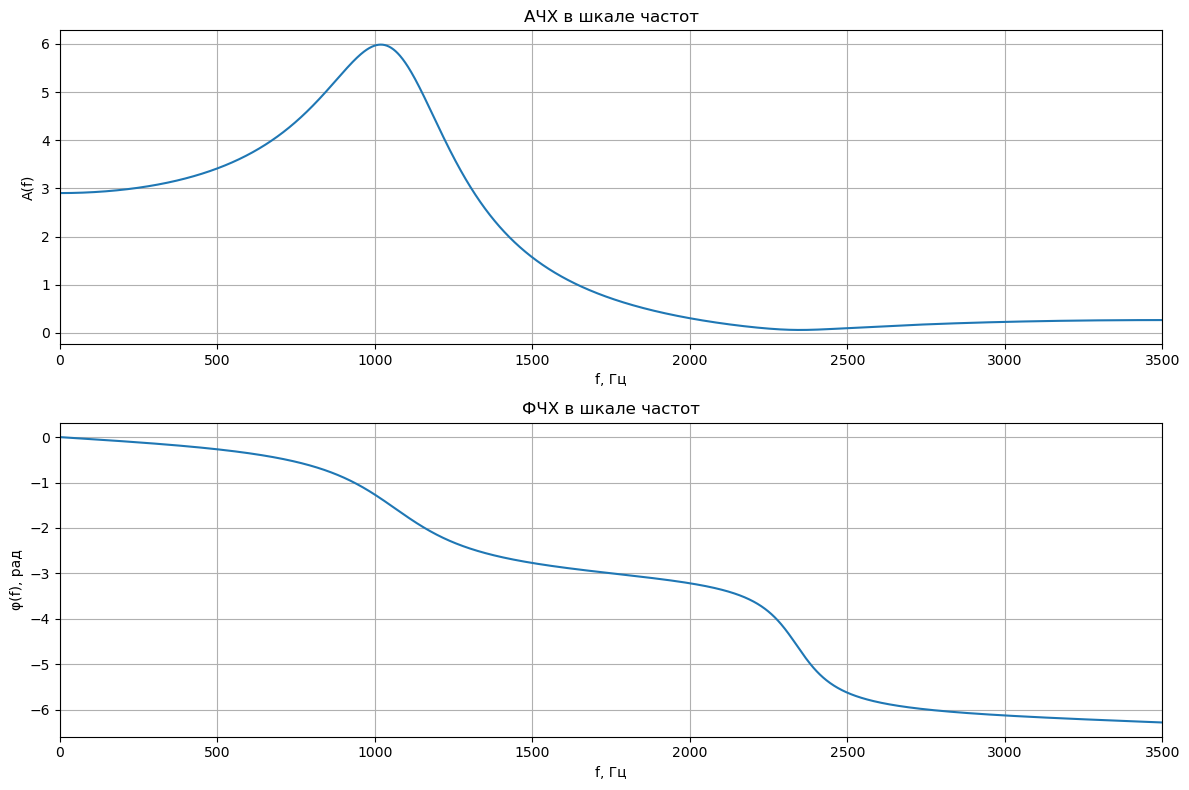

In [10]:
# Перевод нормированной частоты в Гц
f = w * fd / (2 * np.pi)

# Построение графиков
plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)
plt.plot(f, A)
plt.title("АЧХ в шкале частот")
plt.xlabel("f, Гц")
plt.ylabel("A(f)")
plt.xlim(0, fd / 2)
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(f, phi)
plt.title("ФЧХ в шкале частот")
plt.xlabel("f, Гц")
plt.ylabel("φ(f), рад")
plt.xlim(0, fd / 2)
plt.grid()

plt.tight_layout()
plt.show()

##### 7.1 Чему равны границы основной полосы частот?

Основная полоса частот определяется частотой Найквиста:
$$
f_{\max}=\frac{f_d}{2}
$$

Для 7 варианта:
$$
f_{\max}=\frac{7000}{2}=3500\text{ Гц}
$$

Следовательно:
$$
0\leq f\leq3500\text{ Гц}
$$

##### 7.2 Соответствие частотами $\omega$ и $f$

Так как 
$$
f = \frac{w f_d}{2\pi}
$$

Следовательно, графики из шестого и седьмого пунктов имеют одинаковую форму, но разные значения по горизонтальной оси.

### Часть 2

In [3]:
# вычисление значений переменных на основе номера варианта
N_variant = 7
N = 64

fs = 2000 * (N_variant % 5 + 1)
T = 1 / fs

A1 = 1 + 0.01 * N_variant
A2 = 2 * A1

f1 = fs / 8
f2 = 1.5 * f1

phi1 = np.pi / 4
phi2 = np.pi / 8

# Номера гармоник в ДПФ
k1 = f1 * N / fs
k2 = f2 * N / fs

print("fs =", fs)
print("T =", T)
print("A1 =", A1)
print("A2 =", A2)
print("f1 =", f1)
print("f2 =", f2)

fs = 6000
T = 0.00016666666666666666
A1 = 1.07
A2 = 2.14
f1 = 750.0
f2 = 1125.0


In [5]:
def original_signal(t):
    """Исходный непрерывный сигнал. t в секундах (массив или число)."""
    return (A1 * np.cos(2 * np.pi * f1 * t + phi1)
            + A2 * np.cos(2 * np.pi * f2 * t + phi2))


def stems(ax, xs, ys, **kwargs):
    """Дискретные линии спектра/отсчетов без соединяющей ломаной."""
    markerline, stemlines, baseline = ax.stem(xs, ys, basefmt=" ", **kwargs)
    plt.setp(markerline, markersize=4)
    plt.setp(stemlines, linewidth=1.2)
    return markerline, stemlines, baseline

#### Пункт 1

Вычислить амплитудный и фазовый спектры периодической последовательности $x(n)$ с периодом $N$:

$$
x(nT) = A_1 \cos(2\pi f_1 nT + \pi/4) + A_2 \cos(2\pi f_2 nT + \pi/8)
$$

Вывести графики последовательности $x(n)$ на периоде $N$ в шкале дискретного и дискретного нормированного времени.

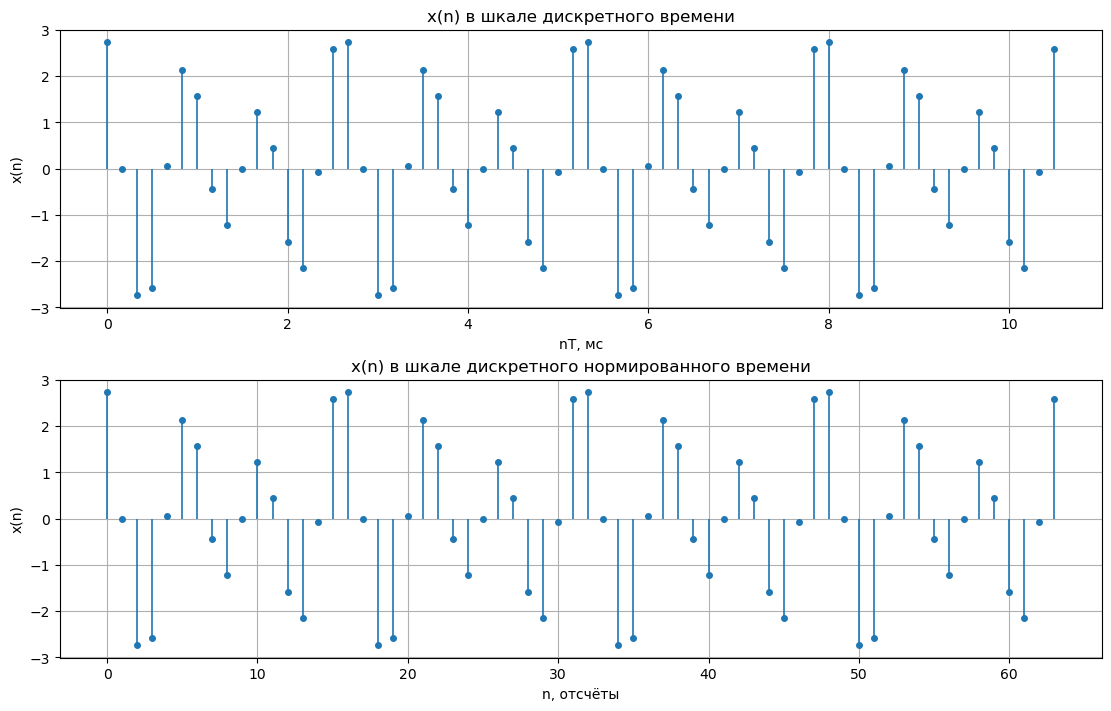

In [6]:
n = np.arange(N)
t_n = n * T
x = original_signal(t_n)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), layout="constrained")
stems(axes[0], t_n * 1e3, x)
axes[0].set(title="x(n) в шкале дискретного времени", xlabel="nT, мс", ylabel="x(n)")
axes[0].grid()
stems(axes[1], n, x)
axes[1].set(title="x(n) в шкале дискретного нормированного времени", xlabel="n, отсчеты", ylabel="x(n)")
axes[1].grid()
plt.show()

Форма графиков одинаковая. Меняется только единица измерения горизонтальной оси.

#### Пункт 2

Вычислить ОДПФ от ДПФ последовательности $x(n)$ и вывести график полученной последовательности в шкале дискретного нормированного времени.

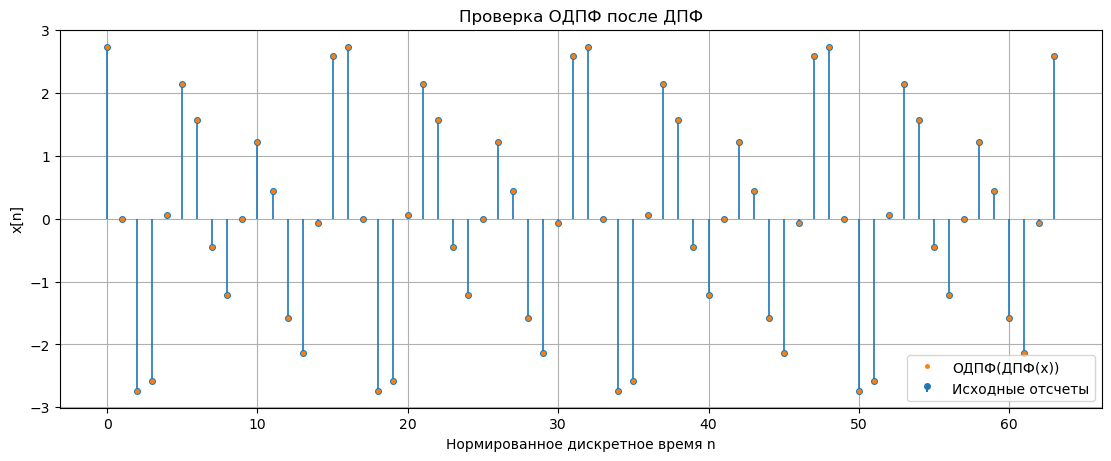

max ошибка: 9.49e-16


In [7]:
X = np.fft.fft(x)  # ДПФ
x_ifft = np.fft.ifft(X)  # ОДПФ
err_ifft = np.max(np.abs(x_ifft - x))
fig, ax = plt.subplots(figsize=(11, 4.5), layout="constrained")
stems(ax, n, x, label="Исходные отсчеты")
ax.plot(n, x_ifft.real, ".", markersize=5, label="ОДПФ(ДПФ(x))")
ax.set(title="Проверка ОДПФ после ДПФ", xlabel="Нормированное дискретное время n", ylabel="x[n]")
ax.legend()
ax.grid()
plt.show()

print(f"max ошибка: {err_ifft:.2e}")

Исходная и восстановленная последовательности совпадают с машинной точностью. Это подтверждает обратимость ДПФ.

#### Пункт 3

Вычислить амплитудный и фазовый спектры последовательности $x(n)$ и вывести их графики в шкалах дискретных нормированных и абсолютных частот. Пояснить:

a. связь дискретного нормированного времени с дискретным временем;
   
b. связь частоты $f$ (Гц) с дискретной нормированной частотой;
   
c. вид амплитудного и фазового спектров.

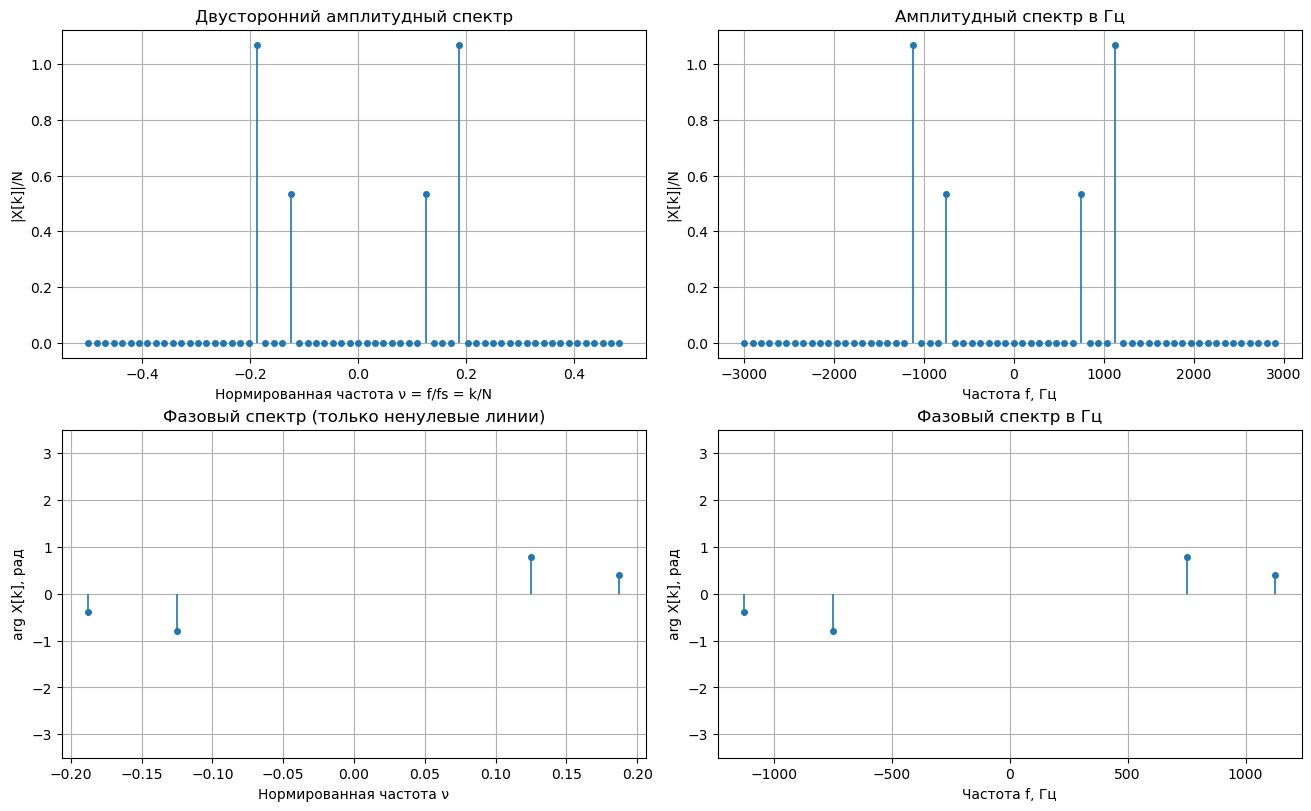

In [9]:
C = X / N
nu = np.fft.fftfreq(N, d=1)  # k/N, циклов на отсчет (f/fs)
freq = np.fft.fftfreq(N, d=T)  # герцы: nu*fs
order = np.argsort(nu)  # диапазон от -0.5 до +0.5
amp = np.abs(C)
strong = amp > np.max(amp) * 1e-8  # нулевые линии не имеют определенной фазы
phase = np.angle(C)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
stems(axes[0, 0], nu[order], amp[order])
axes[0, 0].set(title="Двусторонний амплитудный спектр", xlabel="Нормированная частота ν = f/fs = k/N", ylabel="|X[k]|/N")
axes[0, 0].grid()

stems(axes[0, 1], freq[order], amp[order])
axes[0, 1].set(title="Амплитудный спектр в Гц", xlabel="Частота f, Гц", ylabel="|X[k]|/N")
axes[0, 1].grid()

stems(axes[1, 0], nu[strong], phase[strong])
axes[1, 0].set(title="Фазовый спектр (только ненулевые линии)", xlabel="Нормированная частота ν", ylabel="arg X[k], рад", ylim=(-3.5, 3.5))
axes[1, 0].grid()

stems(axes[1, 1], freq[strong], phase[strong])
axes[1, 1].set(title="Фазовый спектр в Гц", xlabel="Частота f, Гц", ylabel="arg X[k], рад", ylim=(-3.5, 3.5))
axes[1, 1].grid()
plt.show()

##### 3.1 Связь дискретного нормированного времени с дискретным временем.

Дискретное время определяется выражением $t=nT$, где $n$ - номер отсчета, а $T$ - период дискретизации. Дискретное нормированное время представляет собой отношение $t/T=n$, то есть измеряется в отсчетах, а не в секундах.

##### 3.2 Связь абсолютной частоты с дискретной нормированной частотой.
Дискретная нормированная частота определяется по формуле:
$$
\nu=\frac{f}{f_d}=fT
$$

Она показывает отношение частоты гармоники к частоте дискретизации и не имеет единиц измерения.

Для первой гармоники:
$$
\nu_1=\frac{750}{6000}=0.125
$$

Для второй гармоники:
$$
\nu_2=\frac{1125}{6000}=0.1875
$$

Таким образом, нормированным частотам 0.125 и 0.1875 соответствуют абсолютные частоты 750 и 1125 Гц. При построении графиков изменяется только масштаб частотной оси, форма спектров остается одинаковой.

##### 3.3 Вид амплитудного и фазового спектров.

Амплитудный спектр является дискретным и симметричным относительно нулевой частоты. На графике наблюдаются четыре выраженные спектральные линии на частотах $\pm750$ Гц и $\pm1125$ Гц, что соответствует двум гармоникам исходного сигнала.

Амплитуды линий составляют $A_1/2=0.535$ и $A_2/2=1.07$. Деление на два объясняется представлением каждой косинусоидальной гармоники через две комплексные экспоненты с положительной и отрицательной частотами. Остальные значения спектра практически равны нулю.

Фазовый спектр также является дискретным, но обладает антисимметрией относительно нулевой частоты. Для первой гармоники на положительной частоте 750 Гц фаза равна $\pi/4\approx0.785$ рад, для второй гармоники на частоте 1125 Гц - $\pi/8\approx0.393$ рад. На соответствующих отрицательных частотах фазы имеют противоположные знаки.

Фазы спектральных составляющих с практически нулевой амплитудой не имеют физического смысла, поэтому на графике они не отображаются.

#### Пункт 4

Вычислить ДПФ конечной последовательности $x(n)$ длины $N$. Вывести графики в шкале дискретных нормированных частот модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности. Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.

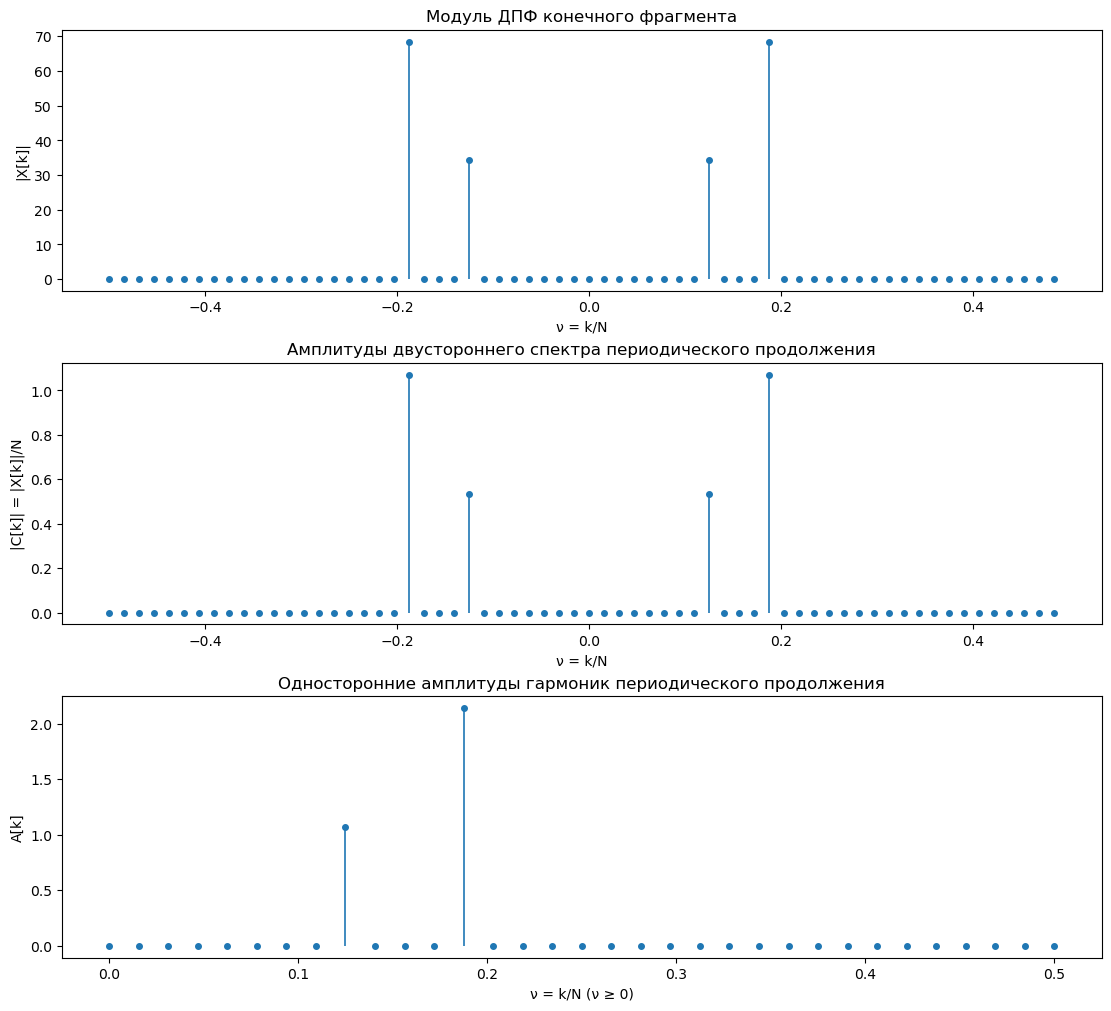

In [11]:
k_pos = np.arange(N // 2 + 1)
nu_pos = k_pos / N
amplitude_one_sided = 2 * np.abs(X[:N // 2 + 1]) / N
amplitude_one_sided[0] /= 2
amplitude_one_sided[-1] /= 2

fig, axes = plt.subplots(3, 1, figsize=(11, 10), layout="constrained")
stems(axes[0], nu[order], np.abs(X[order]))
axes[0].set(title="Модуль ДПФ конечного фрагмента", xlabel="ν = k/N", ylabel="|X[k]|")

stems(axes[1], nu[order], amp[order])
axes[1].set(title="Амплитуды двустороннего спектра периодического продолжения", xlabel="ν = k/N", ylabel="|C[k]| = |X[k]|/N")

stems(axes[2], nu_pos, amplitude_one_sided)
axes[2].set(title="Односторонние амплитуды гармоник периодического продолжения", xlabel="ν = k/N (ν ≥ 0)", ylabel="A[k]")
plt.show()

##### 4.1 Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.

Амплитудный спектр периодической последовательности определяется по формуле:
$$
A(k)=\frac{|X(k)|}{N},
$$

где $X(k)$ - ДПФ конечной последовательности, $N=64$ - количество отсчетов.

Модуль ДПФ конечной последовательности и амплитудный спектр ее периодического продолжения имеют одинаковое расположение спектральных линий, но отличаются масштабом амплитуд.

#### Пункт 5

Восстановить периодический аналоговый сигнал $x(t)$ по отсчетам ДПФ $X(k)$ периодической последовательности $x(n)$. Для вычисления значений сигнала $x(t)$ использовать формулу

$$
x(t) = \frac{1}{N} \sum_{k=-N/2}^{N/2-1} X_a(k) \exp\left(j\frac{2\pi}{NT}kt\right),
$$

где отсчеты $X_a(k)$ связаны с отсчетами ДПФ $X(k)$ соотношением:

$$
X_a(k) = 
\begin{cases} 
X(N+k), & -N/2 \leqslant k \leqslant -1 \\ 
X(k), & 0 \leqslant k \leqslant N/2-1 
\end{cases}
$$

задавая значения времени $t$ на интервале $t \in [0; (N-1)T]$ с шагом $\Delta t = 0.25T$. Вывести графики:

a. периодической последовательности $x(n)$ и модуля ее ДПФ;

b. восстановленного аналогового сигнала $x(t)$ и его амплитудного спектра;

c. исходного аналогового сигнала $x(t) = x(nT) |_{nT=t}$.

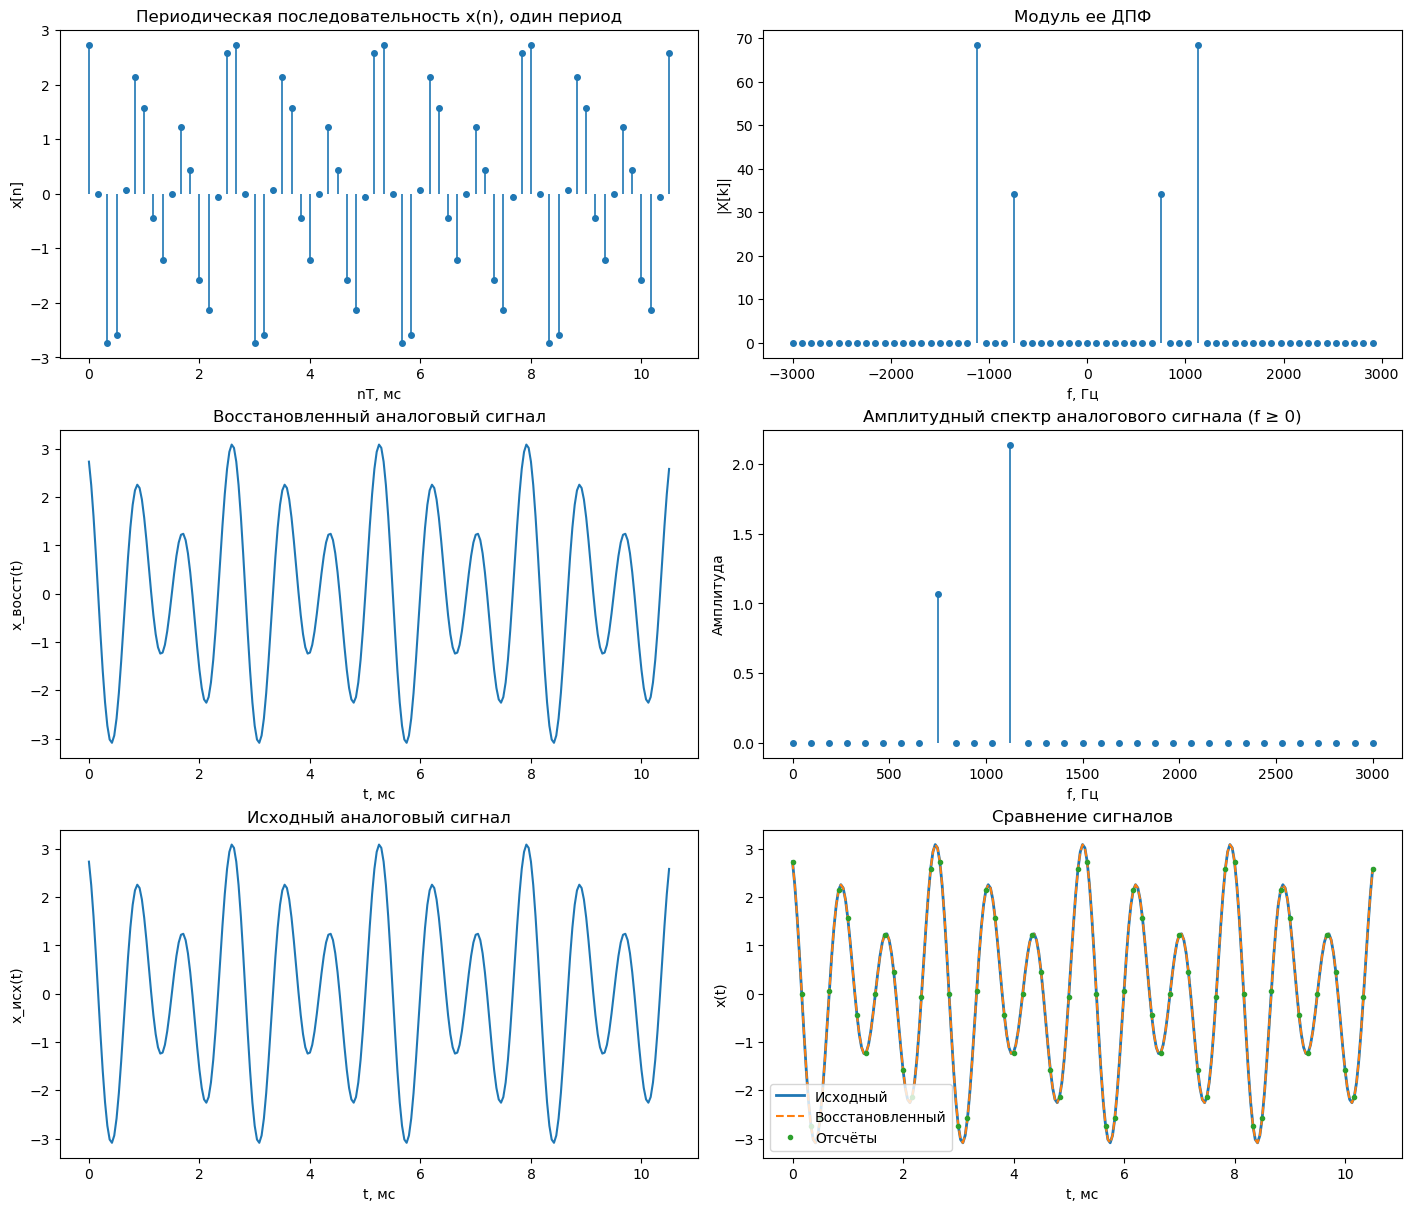

max ошибка (для сравнения сигналов) = 2.89e-14


In [13]:
k_signed = np.arange(-N // 2, N // 2)
source_indices = np.where(k_signed < 0, N + k_signed, k_signed)
X_a = X[source_indices]
t_dense = np.arange(4 * (N - 1) + 1) * (T / 4)
e = np.exp(1j * (2 * np.pi / (N * T)) * np.outer(k_signed, t_dense))
x_restored_complex = (X_a @ e) / N
x_restored = np.real(x_restored_complex)
x_analog = original_signal(t_dense)
max_error = np.max(np.abs(x_restored - x_analog))
max_imag = np.max(np.abs(x_restored_complex.imag))

fig, axes = plt.subplots(3, 2, figsize=(14, 12), layout="constrained")
stems(axes[0, 0], t_n * 1e3, x)
axes[0, 0].set(title="Периодическая последовательность x(n), один период", xlabel="nT, мс", ylabel="x[n]")

stems(axes[0, 1], freq[order], np.abs(X[order]))
axes[0, 1].set(title="Модуль ее ДПФ", xlabel="f, Гц", ylabel="|X[k]|")

axes[1, 0].plot(t_dense * 1e3, x_restored)
axes[1, 0].set(title="Восстановленный аналоговый сигнал", xlabel="t, мс", ylabel="x_восст(t)")

stems(axes[1, 1], k_pos / (N * T), amplitude_one_sided)
axes[1, 1].set(title="Амплитудный спектр аналогового сигнала (f ≥ 0)", xlabel="f, Гц", ylabel="Амплитуда")

axes[2, 0].plot(t_dense * 1e3, x_analog)
axes[2, 0].set(title="Исходный аналоговый сигнал", xlabel="t, мс", ylabel="x_исх(t)")

axes[2, 1].plot(t_dense * 1e3, x_analog, linewidth=2, label="Исходный")
axes[2, 1].plot(t_dense * 1e3, x_restored, "--", label="Восстановленный")
axes[2, 1].plot(t_n * 1e3, x, ".", label="Отсчеты")
axes[2, 1].set(title="Сравнение сигналов", xlabel="t, мс", ylabel="x(t)")
axes[2, 1].legend()
plt.show()

print(f"max ошибка (для сравнения сигналов) = {max_error:.2e}")

#### Пункт 6

Исходя из результатов п. 5, объяснить:

a. связь модуля ДПФ последовательности со спектром аналогового сигнала;

b. результат визуального сравнения восстановленного и исходного сигналов.

##### 6.1 Связь модуля ДПФ последовательности со спектром аналогового сигнала

Модуль ДПФ дискретной последовательности позволяет определить частоты и амплитуды гармоник восстановленного аналогового сигнала.

Частоты спектральных составляющих определяются по формуле:
$$
f_k=\frac{k}{NT},
$$

где $N=64$ - длина последовательности, $T=1/6000$ с - период дискретизации.

Амплитуды гармоник аналогового сигнала определяются по модулю ДПФ с учетом нормировки:
$$
A_k=\frac{2|X(k)|}{N}
$$

для положительных частот ниже частоты Найквиста.

В рассматриваемом случае модуль ДПФ имеет пики на частотах 750 и 1125 Гц со значениями 34.24 и 68.48 соответственно. После нормировки получаем амплитуды аналоговых гармоник 1.07 и 2.14.

Таким образом, модуль ДПФ и односторонний амплитудный спектр восстановленного аналогового сигнала имеют одинаковое расположение спектральных линий, но отличаются масштабом амплитуд. 

##### 6.2 Результат визуального сравнения восстановленного и исходного сигналов

При визуальном сравнении графиков восстановленного и исходного аналоговых сигналов наблюдается их практически полное совпадение. Восстановленный сигнал повторяет форму, амплитуды и временное расположение максимумов и минимумов исходного сигнала.

Это объясняется тем, что исходный сигнал состоит из двух гармоник с частотами 750 и 1125 Гц, которые меньше частоты Найквиста:
$$
f_{\text{Н}}=\frac{f_d}{2}=3000\text{ Гц}.
$$

Кроме того, обе частоты кратны частотному разрешению ДПФ:
$$
\Delta f=\frac{f_d}{N}=\frac{6000}{64}=93{,}75\text{ Гц}.
$$

Незначительные численные расхождения возникают только из-за погрешностей вычислений с плавающей точкой.

#### Пункт 7

Проверить равенство Парсеваля. Пояснить его смысл.

In [14]:
energy_time = np.sum(np.abs(x) ** 2)
energy_freq = np.sum(np.abs(X) ** 2) / N

print(energy_time)
print(energy_freq)

183.18400000000003
183.18400000000003


Для дискретной последовательности равенство Парсеваля имеет вид:

$$
\sum_{n=0}^{N-1}|x[n]|^2
=
\frac1N\sum_{k=0}^{N-1}|X[k]|^2
$$

где:
- $x(n)$ - отсчеты исходной последовательности;
- $X(k)$ - коэффициенты ДПФ;
- $N=64$ - длина последовательности.

Левая часть равенства представляет собой энергию сигнала, вычисленную по его отсчетам во временной области. Правая часть представляет ту же энергию, но вычисленную через коэффициенты ДПФ.

Смысл равенства Парсеваля заключается в том, что при переходе от временного представления сигнала к частотному его энергия не изменяется. ДПФ лишь представляет сигнал в другом виде: вместо значений амплитуды в отдельные моменты времени используются комплексные коэффициенты, характеризующие его частотные составляющие.

Для рассмотренного примера равенство Парсеваля выполняется.

## Выводы

В ходе практической работы были изучены характеристики линейных дискретных систем, методы вычисления их реакций и применение дискретного преобразования Фурье для спектрального анализа сигналов.

В первой части была вычислена импульсная характеристика рекурсивного звена второго порядка, представляющая собой затухающие колебания бесконечной длительности. Реакции системы, полученные методом свертки и по разностному уравнению, практически совпали. Были определены нули и полюсы передаточной функции, исследованы АЧХ и ФЧХ. Установлено, что система устойчива, поскольку ее полюсы расположены внутри единичной окружности.

Во второй части были вычислены ДПФ и ОДПФ последовательности из двух гармоник, построены амплитудные и фазовые спектры. Установлена связь между модулем ДПФ и амплитудным спектром периодического сигнала. Восстановленный аналоговый сигнал практически полностью совпал с исходным благодаря выполнению условия Найквиста и соответствию частот гармоник частотным отсчетам ДПФ.

Также было подтверждено равенство Парсеваля: энергия одного периода сигнала во временной и частотной областях совпала.